# gridfm-trustlayer demo: N-k contingency screening on the IEEE 14-bus grid

A GridFM power-flow model predicts the state of a grid after a contingency in milliseconds, but a point prediction says nothing about its own error. This notebook wraps the model's predictions in **error bars with a guaranteed coverage**, and uses them to screen contingencies against line ratings: which are secure, which are insecure, and which need a full AC power flow to decide.

- **Model:** GENCO small, the released checkpoint [`gridfm/genco-pf-datakit`](https://huggingface.co/gridfm/genco-pf-datakit) `case14_ieee/small/seed0`, used as released. It was trained on N-1 contingencies.
- **Data:** contingency scenarios with one to five outages of branches or generators, generated with [gridfm-datakit](https://github.com/gridfm/gridfm-datakit) and predicted with [gridfm-graphkit](https://github.com/gridfm/gridfm-graphkit), in three separately generated sets: **calibration** (9,723 scenarios), **test** (4,848) and **new** (294, with their AC solution removed). [`README.md`](README.md) describes them.
- **Runs** in under a minute on a laptop, with `pip install "gridfm-trustlayer[datakit]"` (line loading uses gridfm-datakit's branch-flow routine).
- **Scope:** the 14-bus grid keeps the demo small enough to run on a laptop. It shows how the layer works and what it reports; the numbers are specific to this grid, model and data, not a measure of performance on larger systems.

The workflow has three steps: **fit** the layer on the calibration set (`compute`), **validate** it on the test set (`calibrate`, `screen`), and **operate** it on new scenarios (`apply`).

In [1]:
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D

from gridfm_trustlayer import (
    compute_line_loading,
    load_ground_truth,
    load_interval_artifacts,
    load_predictions,
)
from gridfm_trustlayer.cli import main as trustlayer

GRID = "case14_ieee"
DATA = Path("data")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.precision", 4)

## 1. The problem: point predictions get worse with every outage

The model is accurate on N-1, the kind of contingency it was trained on, and much less so beyond. Here are its predicted line loadings (as a fraction of each line's rating) against the AC solution of the test scenarios, by number of outages:

In [2]:
truth = load_ground_truth(
    DATA / "test/raw/bus_data.parquet", DATA / "test/raw/branch_data.parquet"
)
predicted = load_predictions(
    DATA / f"test/{GRID}_predictions.parquet", task_name="PowerFlow"
)
true_loading = compute_line_loading(truth.Vm, truth.Va, truth)
predicted_loading = compute_line_loading(predicted.Vm, predicted.Va, truth)
in_service = (true_loading >= 0) & (predicted_loading >= 0)

rows = []
for k in np.unique(truth.n_outages):
    scenarios = truth.n_outages == k
    t, p = true_loading[scenarios], predicted_loading[scenarios]
    valid = in_service[scenarios]
    error = np.abs(p - t)[valid]
    overloads = (t > 1.0) & valid
    rows.append(
        {
            "outages": int(k),
            "scenarios": int(scenarios.sum()),
            "mean |error|": error.mean(),
            "99th percentile |error|": np.quantile(error, 0.99),
            "overloads": int(overloads.sum()),
            "missed by the point prediction": int((overloads & (p <= 1.0)).sum()),
        }
    )
problem = pd.DataFrame(rows).set_index("outages")
problem

,scenarios,mean |error|,99th percentile |error|,overloads,missed by the point prediction
outages,,,,,
1,1233,6.6366e-05,0.0006,59,0
2,1148,5.4032e-03,0.0799,122,2
3,1032,1.6421e-02,0.2681,196,13
4,870,3.0277e-02,0.3976,229,46
5,565,4.9343e-02,0.5560,200,49


The error grows by orders of magnitude from N-1 to N-5, and screening with the point prediction alone (flag a line when its predicted loading exceeds 1.0) misses real overloads.

## 2. Fit: learn the size of the errors on the calibration set

The layer is described by one YAML file. `strat: n_outages` fits separate bounds for each number of outages, so the error bars can widen with the severity of the contingency. `alpha: 0.1` asks for 90% intervals. `screen_bounds` sets the operating limits; this demo screens line loading, the thermal limit of N-k screening (voltages can be screened too, with `Vm: {lower: 0.95, upper: 1.05}`).

In [3]:
config = OUT / "trust_config.yaml"
config.write_text(f"""\
version: 1
task_name: PowerFlow
cp_type: element
strat: n_outages
alpha: 0.1
variables: [Vm, Va, line_loading]
screen_bounds:
  line_loading: {{upper: 1.0}}      # loading above 100% of the rating

inputs:
  calibration:                      # compute: fit
    predictions: data/calibration/{GRID}_predictions.parquet
    pf_node: data/calibration/raw/bus_data.parquet
    pf_edge: data/calibration/raw/branch_data.parquet
  test:                             # calibrate and screen: validate
    predictions: data/test/{GRID}_predictions.parquet
    pf_node: data/test/raw/bus_data.parquet
    pf_edge: data/test/raw/branch_data.parquet
  apply:                            # apply: operate, no AC solution needed
    predictions: data/new/{GRID}_predictions.parquet
    pf_node: data/new/raw/bus_data.parquet
    pf_edge: data/new/raw/branch_data.parquet

outputs:
  artifact: outputs/{GRID}.trustlayer
  calibrated_predictions: outputs/calibrated
  screen_dir: outputs/screen
  applied_predictions: outputs/applied

commands:
  screen:
    variables: [line_loading]       # the variables with limits above
""")
_ = trustlayer(["compute", "--config", str(config)])

compute: fitted element, strat n_outages for Vm, Va, line_loading on 9,723 calibration scenarios; artifact: outputs/case14_ieee.trustlayer


The command line is the same: `gridfm_trustlayer compute --config outputs/trust_config.yaml`. The artifact in `outputs/` is the fitted layer; everything after this step uses it.

## 3. Validate: do the bounds keep their promise on the test set?

`calibrate` puts bounds on every test prediction and measures how often they contain the true value (the *coverage*), in each stratum. It also writes a report, `outputs/calibrated/coverage/summary.md`.

In [4]:
_ = trustlayer(["calibrate", "--config", str(config)])

coverage = pd.read_csv(OUT / "calibrated/coverage/coverage_by_stratum.csv")
coverage[coverage["variable"] == "line_loading"][
    ["stratum", "coverage", "coverage_low", "coverage_high", "mean_width"]
]

calibrate: Vm: coverage 0.901 (target 0.900), mean width 0.04455 p.u.; lowest stratum n_outages=2 0.892; 16,929 known values not counted


calibrate: Va: coverage 0.902 (target 0.900), mean width 6.249 degrees; lowest stratum n_outages=2 0.891; 4,848 known values not counted


calibrate: line_loading: coverage 0.898 (target 0.900), mean width 0.07472 fraction of rating; lowest stratum n_outages=1 0.885


calibrate: data in outputs/calibrated; reports in outputs/calibrated/coverage


,stratum,coverage,coverage_low,coverage_high,mean_width
12,all,0.8977,0.8892,0.9062,0.0747
13,n_outages=1,0.8854,0.8676,0.9032,0.0003
14,n_outages=2,0.8917,0.8737,0.9097,0.0150
15,n_outages=3,0.9031,0.8850,0.9211,0.0690
16,n_outages=4,0.9166,0.8983,0.9350,0.1689
17,n_outages=5,0.9026,0.8782,0.9271,0.2677


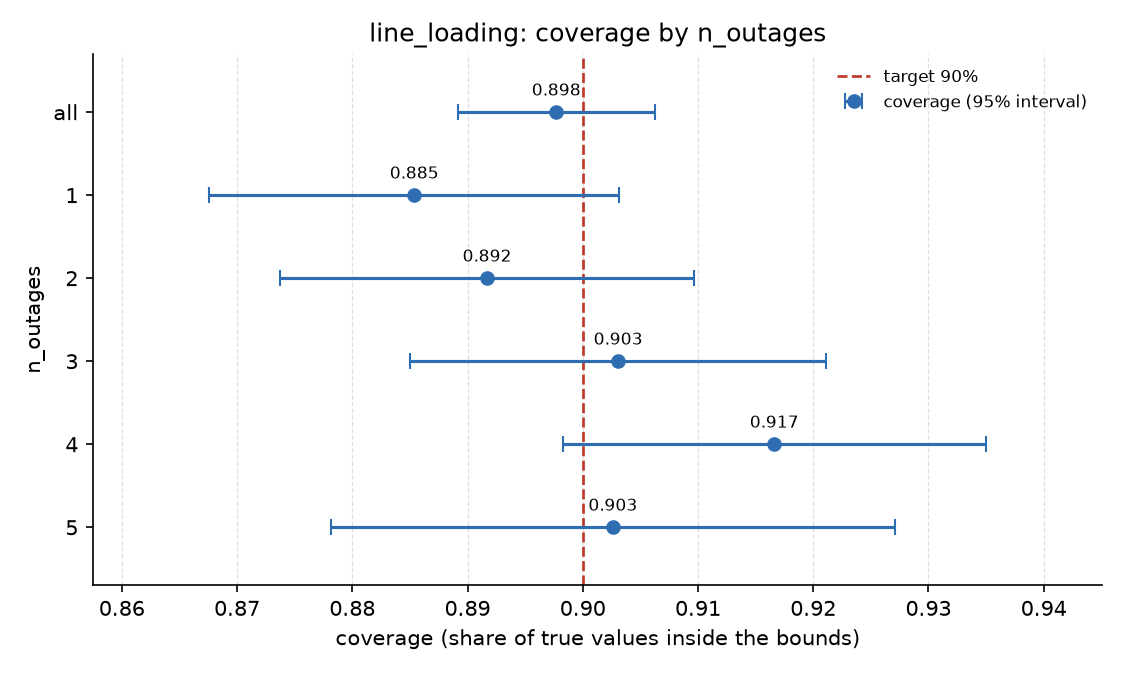

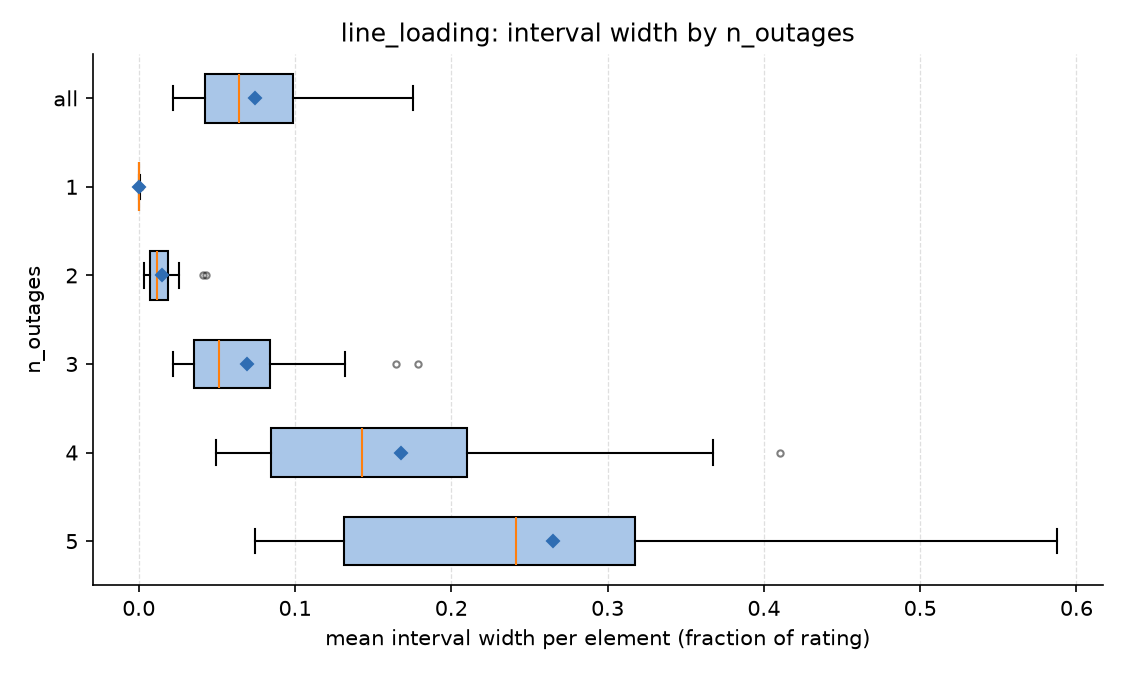

In [5]:
display(
    Image(
        OUT / "calibrated/coverage/figures/line_loading_coverage_by_stratum.png",
        width=560,
    )
)
display(
    Image(
        OUT / "calibrated/coverage/figures/line_loading_width_by_stratum.png", width=560
    )
)

Coverage is close to the 90% target in every stratum, within the sampling interval of the estimate, while the bounds widen with the number of outages, as the errors do. Known values (the voltage set-points of PV buses and the reference angle) are left out of every number.

### Why stratify, and by what?

The same layer with one set of bounds per line for all contingencies (no `strat`), against the strata by number of outages, contingency level by contingency level:

In [6]:
def variant(name, strat_line):
    """The layer of section 2 with another `strat` line, fitted and applied to the test set."""
    path = OUT / f"trust_config_{name}.yaml"
    path.write_text(
        config.read_text()
        .replace("strat: n_outages\n", strat_line)
        .replace(f"outputs/{GRID}.trustlayer", f"outputs/{name}/{GRID}.trustlayer")
        .replace("outputs/calibrated", f"outputs/{name}/calibrated")
        + "save_figures: false\n"
    )
    with redirect_stdout(StringIO()):  # the comparison below is what matters here
        trustlayer(["compute", "--config", str(path)])
        trustlayer(["calibrate", "--config", str(path)])
    rows = pd.read_parquet(
        OUT
        / f"{name}/calibrated/{GRID}_predictions_line_loading_with_intervals.parquet"
    )
    return rows[(rows["line_loading_target"] >= 0) & (rows["line_loading_pred"] >= 0)]


outages = pd.Series(truth.n_outages, index=truth.scenario_ids)
setups = {
    "one set": variant("flat", ""),
    "n_outages": pd.read_parquet(
        OUT / f"calibrated/{GRID}_predictions_line_loading_with_intervals.parquet"
    ).query("line_loading_target >= 0 and line_loading_pred >= 0"),
}
coverage_by_k, width_by_k = {}, {}
for name, rows in setups.items():
    k = rows["scenario"].map(outages).rename("outages")
    covered = rows["line_loading_target"].between(
        rows["line_loading_pi_lower"], rows["line_loading_pi_upper"]
    )
    width = rows["line_loading_pi_upper"] - rows["line_loading_pi_lower"]
    coverage_by_k[name] = covered.groupby(k).mean()
    width_by_k[name] = width.groupby(k).mean()
coverage_by_k, width_by_k = pd.DataFrame(coverage_by_k), pd.DataFrame(width_by_k)
display(Markdown("**Coverage**, by number of outages:"), coverage_by_k.round(3))
display(Markdown("**Mean width**, by number of outages:"), width_by_k.round(4))
display(
    Markdown(
        f"With one set of bounds, coverage is {coverage_by_k['one set'].iloc[-1]:.0%} at N-5, far below the 90% target, "
        f"and {coverage_by_k['one set'].iloc[0]:.0%} at N-1, with bounds "
        f"{width_by_k['one set'].iloc[0] / width_by_k['n_outages'].iloc[0]:.0f} times wider than needed there: the 90% "
        "holds only on average over the contingencies, and the bounds are too narrow exactly where the model is weakest. "
        "Strata should follow what the errors depend on; for N-k screening, that is the number of outages."
    )
)

**Coverage**, by number of outages:

,one set,n_outages
outages,,
1,0.999,0.885
2,0.972,0.892
3,0.896,0.903
4,0.819,0.917
5,0.694,0.903


**Mean width**, by number of outages:

,one set,n_outages
outages,,
1,0.0630,0.0003
2,0.0631,0.0150
3,0.0631,0.0690
4,0.0628,0.1689
5,0.0629,0.2677


With one set of bounds, coverage is 69% at N-5, far below the 90% target, and 100% at N-1, with bounds 250 times wider than needed there: the 90% holds only on average over the contingencies, and the bounds are too narrow exactly where the model is weakest. Strata should follow what the errors depend on; for N-k screening, that is the number of outages.

What the stratified bounds look like near the rating, where they decide: the line with the most overloads, in the 40 N-3 test scenarios where its predicted loading is closest to 1.0.

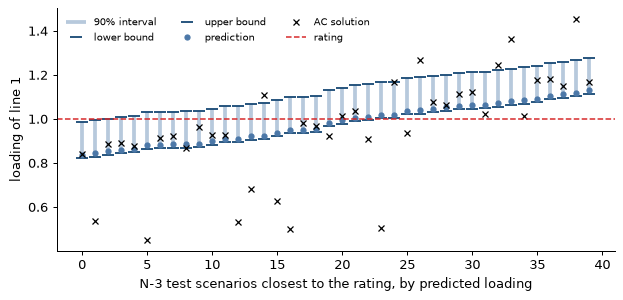

Each bar is the whole 90% interval, from the lower to the upper bound. Here the lower bound is 0.0155 below the prediction and the upper bound 0.1491 above it (medians): in N-3 contingencies the model rarely overestimates the loading of line 1, so the interval opens upward. Conformal bounds follow the shape of the errors, which need not be symmetric. Some true values fall outside their interval, as about 10% of them should.

In [7]:
lines = pd.read_parquet(
    OUT / f"calibrated/{GRID}_predictions_line_loading_with_intervals.parquet"
)
n3 = lines[(lines["n_outages"] == 3) & (lines["line_loading_target"] >= 0)]
branch = (n3["line_loading_target"] > 1.0).groupby(n3["branch"]).sum().idxmax()
sample = n3[n3["branch"] == branch]
sample = (
    sample.loc[(sample["line_loading_pred"] - 1.0).abs().nsmallest(40).index]
    .sort_values("line_loading_pred")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(sample))
ax.vlines(
    x,
    sample["line_loading_pi_lower"],
    sample["line_loading_pi_upper"],
    color="#4c78a8",
    lw=3,
    alpha=0.4,
    label="90% interval",
)
ax.plot(
    x,
    sample["line_loading_pi_lower"],
    "_",
    color="#1f4e79",
    ms=9,
    mew=1.5,
    label="lower bound",
)
ax.plot(
    x,
    sample["line_loading_pi_upper"],
    "_",
    color="#1f4e79",
    ms=9,
    mew=1.5,
    label="upper bound",
)
ax.plot(x, sample["line_loading_pred"], "o", color="#4c78a8", ms=4, label="prediction")
ax.plot(x, sample["line_loading_target"], "x", color="black", ms=5, label="AC solution")
ax.axhline(1.0, color="#d62728", ls="--", lw=1.2, label="rating")
ax.set_xlabel("N-3 test scenarios closest to the rating, by predicted loading")
ax.set_ylabel(f"loading of line {branch}")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

lower_gap = (sample["line_loading_pred"] - sample["line_loading_pi_lower"]).median()
upper_gap = (sample["line_loading_pi_upper"] - sample["line_loading_pred"]).median()
lower_text = (
    f"at the prediction (within {abs(lower_gap):.4f})"
    if abs(lower_gap) < 0.1 * upper_gap
    else f"{lower_gap:.4f} below the prediction"
)
display(
    Markdown(
        f"Each bar is the whole 90% interval, from the lower to the upper bound. Here the lower bound is "
        f"{lower_text} and the upper bound {upper_gap:.4f} above it (medians): in N-3 contingencies the model "
        f"rarely overestimates the loading of line {branch}, so the interval opens upward. Conformal bounds "
        "follow the shape of the errors, which need not be symmetric. Some true values fall outside their "
        "interval, as about 10% of them should."
    )
)

## 4. Screen: secure, uncertain or insecure?

`screen` compares the bounds with the limits. A value whose whole interval lies inside its limits is **within limits**; one whose whole interval lies beyond a limit is a **violation**; one whose interval straddles a limit is **uncertain**. A scenario takes the worst status of its values: **secure**, **uncertain** or **insecure**. Only the uncertain ones need an AC power flow to decide. On the test set every status is checked against the true solution, and the point prediction is screened the same way for comparison.

In [8]:
_ = trustlayer(["screen", "--config", str(config)])

status = pd.read_csv(OUT / "screen/status_by_stratum.csv")
overall = status[
    (status["level"] == "scenario")
    & (status["variable"] == "all")
    & (status["stratum"] == "all")
]
overall = overall.assign(
    wrong=np.select(
        [overall["status"] == "insecure", overall["status"] == "secure"],
        [overall["n"] - overall["truly_violated"], overall["truly_violated"]],
        0,
    )
)
display(
    overall[["method", "status", "n", "wrong"]].rename(
        columns={"n": "scenarios", "wrong": "wrong vs the AC solution"}
    )
)

cell = overall.set_index(["method", "status"])
total = int(cell.loc["interval", "n"].sum())
display(
    Markdown(
        f"Of the {total:,} test scenarios, the intervals call {cell.loc[('interval', 'secure'), 'n']:,} secure and "
        f"{cell.loc[('interval', 'insecure'), 'n']:,} insecure, and get {cell.loc[('interval', 'secure'), 'wrong']} and "
        f"{cell.loc[('interval', 'insecure'), 'wrong']} of them wrong; the other {cell.loc[('interval', 'uncertain'), 'n']:,} "
        f"({cell.loc[('interval', 'uncertain'), 'n'] / total:.0%}) are uncertain and go to an AC power flow. The point "
        f"prediction calls {cell.loc[('point', 'secure'), 'n']:,} scenarios secure, "
        f"{cell.loc[('point', 'secure'), 'wrong']} of them wrongly: contingencies with an overload that it would let through."
    )
)

screen: line_loading (upper limit): 781 of 806 true violations flagged (25 missed), 559 false alarms in 86,493 values


screen: scenarios: 3,710 secure (7 truly insecure), 473 uncertain, 665 insecure (14 truly secure); point prediction: 4,135 secure (74 truly insecure), 713 insecure (32 truly secure)


screen: reports in outputs/screen


,method,status,scenarios,wrong vs the AC solution
0,interval,secure,3710,7
1,interval,uncertain,473,0
2,interval,insecure,665,14
3,point,secure,4135,74
4,point,insecure,713,32


Of the 4,848 test scenarios, the intervals call 3,710 secure and 665 insecure, and get 7 and 14 of them wrong; the other 473 (10%) are uncertain and go to an AC power flow. The point prediction calls 4,135 scenarios secure, 74 of them wrongly: contingencies with an overload that it would let through.

### The overloads the point prediction misses

Every line overload of the test set whose predicted loading stays below the rating, so that the point prediction raises no alarm, with its 90% interval:

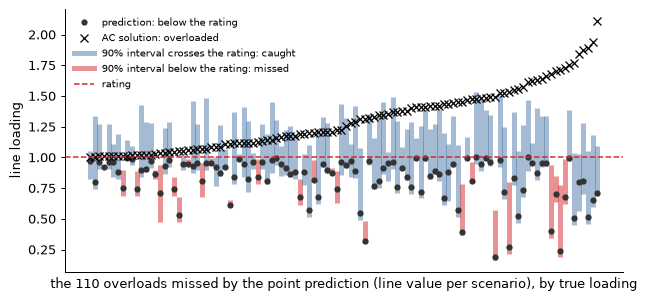

The point prediction misses 110 of the 806 line overloads of the test set. For 85 of them the interval crosses the rating, so the scenario is at least uncertain and goes to an AC power flow. The bounds miss the other 25 too: the model was far off there, the upper tail that 90% bounds leave out. For 9 of them, no other line flags the scenario either, and it is called secure.

**Line overloads by number of outages**, and how many each screen lets through:

,overloads,missed by the point prediction,missed by the intervals
outages,,,
1,59,0,0
2,122,2,2
3,196,13,6
4,229,46,12
5,200,49,5


In [9]:
detail = pd.read_parquet(OUT / "screen/screening_detail_line_loading.parquet")
overloads = detail[detail["true_upper_violation"]]
missed = (
    overloads[overloads["point_status"] == "within_limits"]
    .sort_values("target")
    .reset_index(drop=True)
)
caught = missed["status"] != "within_limits"

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(missed))
ax.vlines(
    x,
    missed["pi_lower"],
    missed["pi_upper"],
    colors=np.where(caught, "#4c78a8", "#d62728"),
    lw=4,
    alpha=0.5,
)
ax.plot(x, missed["pred"], "o", color="#333333", ms=4)
ax.plot(x, missed["target"], "x", color="black", ms=6)
ax.axhline(1.0, color="#d62728", ls="--", lw=1.2)
ax.set_xticks([])
ax.set_xlabel(
    f"the {len(missed)} overloads missed by the point prediction (line value per scenario), by true loading"
)
ax.set_ylabel("line loading")
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            color="#333333",
            marker="o",
            ls="",
            ms=4,
            label="prediction: below the rating",
        ),
        Line2D(
            [],
            [],
            color="black",
            marker="x",
            ls="",
            ms=6,
            label="AC solution: overloaded",
        ),
        Line2D(
            [],
            [],
            color="#4c78a8",
            lw=4,
            alpha=0.5,
            label="90% interval crosses the rating: caught",
        ),
        Line2D(
            [],
            [],
            color="#d62728",
            lw=4,
            alpha=0.5,
            label="90% interval below the rating: missed",
        ),
        Line2D([], [], color="#d62728", ls="--", lw=1.2, label="rating"),
    ],
    frameon=False,
    fontsize=8,
    loc="upper left",
)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

scenarios = pd.read_csv(OUT / "screen/scenarios.csv").set_index("scenario")
lost = missed.loc[~caught, "scenario"]
flagged = scenarios.loc[lost, "status"].ne("secure").sum()
display(
    Markdown(
        f"The point prediction misses {len(missed)} of the {len(overloads)} line overloads of the test set. For "
        f"{caught.sum()} of them the interval crosses the rating, so the scenario is at least uncertain and goes to "
        f"an AC power flow. The bounds miss the other {(~caught).sum()} too: the model was far off there, the upper "
        "tail that 90% bounds leave out. "
        + (
            "Their scenarios are flagged anyway, by another line, so no insecure scenario is called secure."
            if flagged == len(lost)
            else f"For {len(lost) - flagged} of them, no other line flags the scenario either, and it is called secure."
        )
    )
)
display(
    Markdown(
        "**Line overloads by number of outages**, and how many each screen lets through:"
    )
)
display(
    overloads.groupby("n_outages")
    .agg(
        overloads=("target", "size"),
        point=("point_status", lambda status: (status == "within_limits").sum()),
        intervals=("status", lambda status: (status == "within_limits").sum()),
    )
    .rename(
        columns={
            "point": "missed by the point prediction",
            "intervals": "missed by the intervals",
        }
    )
    .rename_axis("outages")
)

The same tables by stratum and per line are in `outputs/screen/summary.md`, with the classic alarm counts per line:

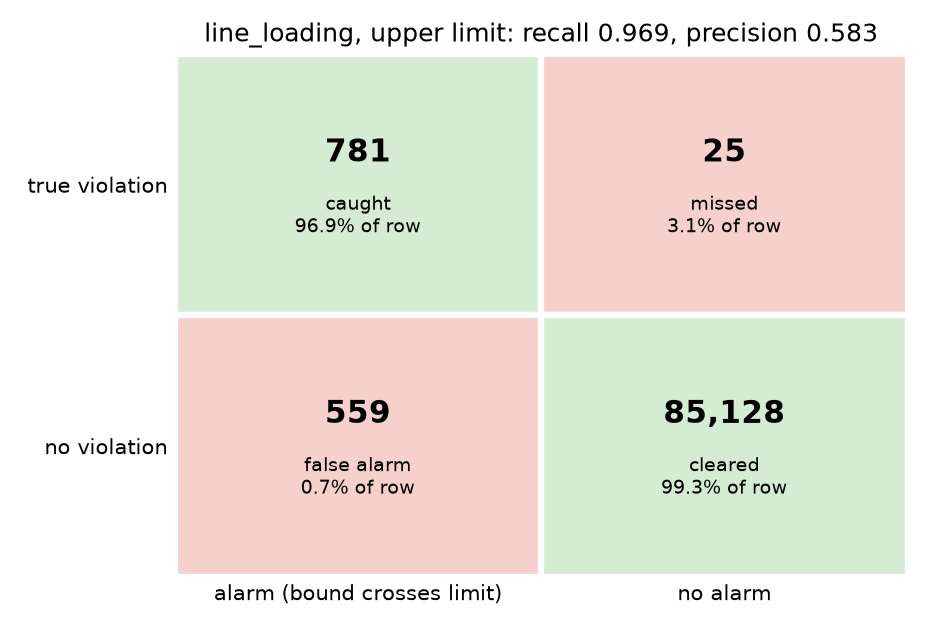

In [10]:
display(Image(OUT / "screen/figures/line_loading_confusion.png", width=480))

## 5. Operate: new scenarios, without their AC solution

For scenarios nobody has solved, `apply` gives the same bounds and statuses. It reads only the predictions (with the set-points, which are inputs of a power flow) and the description of each scenario: its topology, loads and line parameters, no solved values.

In [11]:
_ = trustlayer(["apply", "--config", str(config)])

new = pd.read_csv(OUT / "applied/status/scenarios.csv")
display(new["status"].value_counts().rename("scenarios").to_frame())
new[new["status"] == "uncertain"][
    ["scenario", "n_outages", "status", "point_status", "line_loading_n_uncertain"]
].head(10)

apply: bounds for Vm, Va, line_loading in 294 scenarios; outputs in outputs/applied


apply: scenarios: 221 secure, 25 uncertain, 48 insecure; point prediction: 245 secure, 49 insecure


apply: status report in outputs/applied/status


,scenarios
status,
secure,221
insecure,48
uncertain,25


,scenario,n_outages,status,point_status,line_loading_n_uncertain
10,10,5,uncertain,secure,1
17,17,5,uncertain,secure,1
34,34,4,uncertain,secure,1
47,47,5,uncertain,secure,1
85,85,4,uncertain,secure,1
89,89,4,uncertain,secure,1
94,94,5,uncertain,secure,1
106,106,4,uncertain,secure,1
107,107,5,uncertain,secure,1
109,109,5,uncertain,secure,1


The uncertain scenarios are the ones to send to an AC power flow. The rates `screen` measured on the test set (how often *secure* and *insecure* were wrong) are the ones to expect here. The report is `outputs/applied/status/summary.md`.

## Going further

Sections 1 to 5 are the whole workflow. The rest looks closer at the results: bounds that adapt to each scenario, how to choose `alpha`, and where the coverage guarantee says less than it seems.

### 6. Kernel-weighted bounds, using the model's embeddings

`cp_type: kernel` adapts the margin to each scenario, using how similar its embedding (the model's internal representation of the grid state) is to the calibration scenarios. `n_eff_target: auto` chooses how local the weighting is by cross-validation on the calibration set. The demo data includes the embeddings, averaged per scenario.

In [12]:
kernel_config = OUT / "trust_config_kernel.yaml"
kernel_config.write_text(
    config.read_text()
    .replace(
        "cp_type: element",
        "cp_type: kernel\nn_eff_target: auto\ntuning:\n  grid: [100, 200, 400, 800, 1600]",
    )
    .replace(
        "    pf_edge: data/calibration/raw/branch_data.parquet",
        f"    pf_edge: data/calibration/raw/branch_data.parquet\n    embeddings: data/calibration/{GRID}_embeddings.parquet",
    )
    .replace(
        "    pf_edge: data/test/raw/branch_data.parquet",
        f"    pf_edge: data/test/raw/branch_data.parquet\n    embeddings: data/test/{GRID}_embeddings.parquet",
    )
    .replace(f"outputs/{GRID}.trustlayer", f"outputs/kernel/{GRID}.trustlayer")
    .replace("outputs/calibrated", "outputs/kernel/calibrated")
    .replace("outputs/screen", "outputs/kernel/screen")
    .replace("outputs/applied", "outputs/kernel/applied")
    + "save_figures: false\n"
)
_ = trustlayer(["compute", "--config", str(kernel_config)])
_ = trustlayer(["calibrate", "--config", str(kernel_config)])

line_kernel = load_interval_artifacts(str(OUT / f"kernel/{GRID}.trustlayer"))["line"]
tuned = line_kernel.n_eff_target
per_level = np.unique(line_kernel.calibration_strata, return_counts=True)[1]
display(
    Markdown(
        f"The cross-validation chose `n_eff_target` = {tuned:g}: each test scenario weighs the calibration scenarios "
        f"of its contingency level ({per_level.min():,} to {per_level.max():,} per level) by how much they resemble "
        f"it, so that the weights amount to about {tuned:g} scenarios. The fewer, the more local the bounds."
    )
)

kernel = pd.read_csv(OUT / "kernel/calibrated/coverage/coverage_by_stratum.csv")
both = coverage.merge(
    kernel, on=["variable", "stratum"], suffixes=(" element", " kernel")
)
both = both[both["variable"] == "line_loading"].set_index("stratum")
display(
    both[
        [
            "coverage element",
            "coverage kernel",
            "mean_width element",
            "mean_width kernel",
        ]
    ]
)
display(
    Markdown(
        f"Over the test set, the kernel's bounds are {both.loc['all', 'mean_width kernel']:.3f} wide on average, "
        f"against {both.loc['all', 'mean_width element']:.3f} for `element`, at a coverage of "
        f"{both.loc['all', 'coverage kernel']:.1%} (`element`: {both.loc['all', 'coverage element']:.1%})."
    )
)

kernel tuning (volt): n_eff_target = 400, distance = euclidean (narrowest eligible candidate; 5 candidates, grid search, 5 grouped folds). Report: outputs/kernel/case14_ieee_kernel_tuning.csv
kernel tuning (line): n_eff_target = 400, distance = euclidean (narrowest eligible candidate; 5 candidates, grid search, 5 grouped folds). Report: outputs/kernel/case14_ieee_kernel_tuning.csv
compute: fitted kernel, strat n_outages for Vm, Va, line_loading on 9,723 calibration scenarios; artifact: outputs/kernel/case14_ieee.trustlayer


calibrate: Vm: coverage 0.931 (target 0.900), mean width 0.02129 p.u.; lowest stratum n_outages=1 0.917; 16,929 known values not counted


calibrate: Va: coverage 0.934 (target 0.900), mean width 3.796 degrees; lowest stratum n_outages=1 0.900; 4,848 known values not counted


calibrate: line_loading: coverage 0.929 (target 0.900), mean width 0.04905 fraction of rating; lowest stratum n_outages=1 0.900


calibrate: kernel: in 20% of scenarios, at least one value uses the stratum quantile instead of the kernel's (kcp_fallback)


calibrate: data in outputs/kernel/calibrated; reports in outputs/kernel/calibrated/coverage


The cross-validation chose `n_eff_target` = 400: each test scenario weighs the calibration scenarios of its contingency level (1,212 to 2,530 per level) by how much they resemble it, so that the weights amount to about 400 scenarios. The fewer, the more local the bounds.

,coverage element,coverage kernel,mean_width element,mean_width kernel
stratum,,,,
all,0.8977,0.9286,0.0747,0.0491
n_outages=1,0.8854,0.8999,0.0003,0.0002
n_outages=2,0.8917,0.9309,0.0150,0.0138
n_outages=3,0.9031,0.9422,0.0690,0.0502
n_outages=4,0.9166,0.9490,0.1689,0.1003
n_outages=5,0.9026,0.9381,0.2677,0.1735


Over the test set, the kernel's bounds are 0.049 wide on average, against 0.075 for `element`, at a coverage of 92.9% (`element`: 89.8%).

How the kernel adapts the bars: the same 40 N-3 scenarios as before, with the bounds of both methods. Within a stratum, `element` gives a line the same margins in every scenario; the kernel gives each scenario its own, from the calibration scenarios that resemble it.

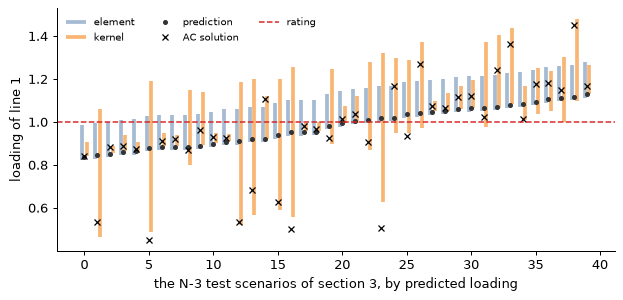

Here every `element` interval has width 0.165, while the kernel's range from 0.032 to 0.702: wide where the scenario resembles calibration scenarios the model got wrong, narrow elsewhere. Of these 40 true values, `element` covers 21 and the kernel 35 (a sample chosen near the rating, so these shares are not the coverage of the test set, which the table above gives).

In [13]:
kernel_lines = pd.read_parquet(
    OUT / f"kernel/calibrated/{GRID}_predictions_line_loading_with_intervals.parquet"
)
bounds = ["line_loading_pi_lower", "line_loading_pi_upper"]
pair = sample.merge(
    kernel_lines.loc[kernel_lines["branch"] == branch, ["scenario", *bounds]],
    on="scenario",
    suffixes=("", "_kernel"),
)

fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(pair))
ax.vlines(
    x - 0.18,
    pair["line_loading_pi_lower"],
    pair["line_loading_pi_upper"],
    color="#4c78a8",
    lw=3,
    alpha=0.5,
    label="element",
)
ax.vlines(
    x + 0.18,
    pair["line_loading_pi_lower_kernel"],
    pair["line_loading_pi_upper_kernel"],
    color="#f58518",
    lw=3,
    alpha=0.6,
    label="kernel",
)
ax.plot(x, pair["line_loading_pred"], "o", color="#333333", ms=3, label="prediction")
ax.plot(x, pair["line_loading_target"], "x", color="black", ms=5, label="AC solution")
ax.axhline(1.0, color="#d62728", ls="--", lw=1.2, label="rating")
ax.set_xlabel("the N-3 test scenarios of section 3, by predicted loading")
ax.set_ylabel(f"loading of line {branch}")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

element_width = pair["line_loading_pi_upper"] - pair["line_loading_pi_lower"]
kernel_width = (
    pair["line_loading_pi_upper_kernel"] - pair["line_loading_pi_lower_kernel"]
)
truth_value = pair["line_loading_target"]
covered_element = truth_value.between(
    pair["line_loading_pi_lower"], pair["line_loading_pi_upper"]
).sum()
covered_kernel = truth_value.between(
    pair["line_loading_pi_lower_kernel"], pair["line_loading_pi_upper_kernel"]
).sum()
display(
    Markdown(
        f"Here every `element` interval has width {element_width.median():.3f}, while the kernel's range from "
        f"{kernel_width.min():.3f} to {kernel_width.max():.3f}: wide where the scenario resembles calibration "
        f"scenarios the model got wrong, narrow elsewhere. Of these {len(pair)} true values, `element` covers "
        f"{covered_element} and the kernel {covered_kernel} (a sample chosen near the rating, so these shares are "
        "not the coverage of the test set, which the table above gives)."
    )
)

Unlike `element`, the kernel's coverage is not guaranteed in finite samples: validating it on the test set, as here, is what tells you whether its narrower or wider bounds can be trusted. See [Kernel-weighted calibration](https://gridfm.github.io/gridfm-trustlayer/user-guide/kernel/).

#### Screening with the kernel's bounds

The screen of section 4, with the kernel's bounds instead, and the overloads the point prediction misses with the intervals of both methods:

screen: line_loading (upper limit): 799 of 806 true violations flagged (7 missed), 486 false alarms in 86,493 values


screen: scenarios: 3,859 secure (1 truly insecure), 330 uncertain, 659 insecure (2 truly secure); point prediction: 4,135 secure (74 truly insecure), 713 insecure (32 truly secure)


screen: reports in outputs/kernel/screen


**Test scenarios by status**:

,secure,"secure, wrongly",uncertain: AC power flow,insecure,"insecure, wrongly"
element,3710,7,473,665,14
kernel,3859,1,330,659,2


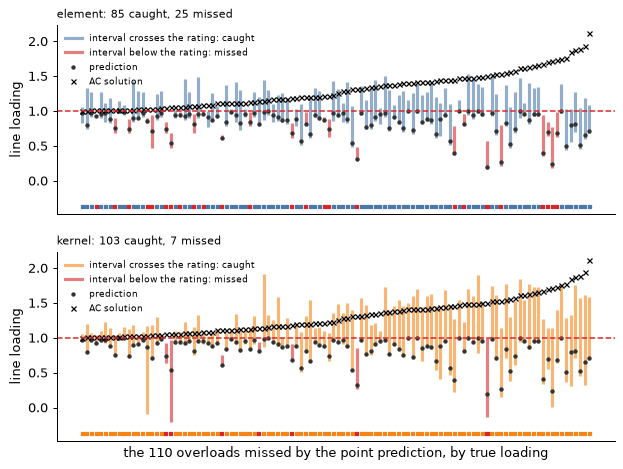

Of the 110 overloads the point prediction misses, `element` catches 85 and the kernel 103, while sending fewer scenarios to an AC power flow (330 against 473) and calling 2 secure scenarios insecure (`element`: 14). Its intervals are narrow where the model is reliable, which leaves room to widen them where it is not.

In [14]:
_ = trustlayer(["screen", "--config", str(kernel_config)])


def scenario_statuses(directory):
    table = pd.read_csv(directory / "status_by_stratum.csv")
    rows = table[
        (table["level"] == "scenario")
        & (table["variable"] == "all")
        & (table["stratum"] == "all")
        & (table["method"] == "interval")
    ].set_index("status")
    return {
        "secure": rows.loc["secure", "n"],
        "secure, wrongly": rows.loc["secure", "truly_violated"],
        "uncertain: AC power flow": rows.loc["uncertain", "n"],
        "insecure": rows.loc["insecure", "n"],
        "insecure, wrongly": rows.loc["insecure", "n"]
        - rows.loc["insecure", "truly_violated"],
    }


statuses = pd.DataFrame(
    {
        "element": scenario_statuses(OUT / "screen"),
        "kernel": scenario_statuses(OUT / "kernel/screen"),
    }
).T
display(Markdown("**Test scenarios by status**:"), statuses)

kernel_detail = pd.read_parquet(
    OUT / "kernel/screen/screening_detail_line_loading.parquet"
)
pairs = missed.merge(
    kernel_detail[["scenario", "branch", "pi_lower", "pi_upper", "status"]],
    on=["scenario", "branch"],
    suffixes=("", "_kernel"),
)
caught_element = pairs["status"] != "within_limits"
caught_kernel = pairs["status_kernel"] != "within_limits"

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, sharey=True)
x = np.arange(len(pairs))
panels = (
    ("element", pairs["pi_lower"], pairs["pi_upper"], caught_element, "#4c78a8"),
    (
        "kernel",
        pairs["pi_lower_kernel"],
        pairs["pi_upper_kernel"],
        caught_kernel,
        "#f58518",
    ),
)
for ax, (method, lower, upper, caught_by, color) in zip(axes, panels):
    ax.vlines(
        x, lower, upper, colors=np.where(caught_by, color, "#d62728"), lw=2.5, alpha=0.6
    )
    ax.plot(x, pairs["pred"], "o", color="#333333", ms=2.5)
    ax.plot(x, pairs["target"], "x", color="black", ms=4)
    ax.axhline(1.0, color="#d62728", ls="--", lw=1.2)
    # Some intervals are too narrow to see: a strip at the bottom shows each verdict.
    ax.scatter(
        x,
        np.full(len(x), 0.04),
        marker="s",
        s=6,
        transform=ax.get_xaxis_transform(),
        c=np.where(caught_by, color, "#d62728"),
    )
    ax.set_ylabel("line loading")
    ax.set_title(
        f"{method}: {caught_by.sum()} caught, {(~caught_by).sum()} missed",
        fontsize=9,
        loc="left",
    )
    ax.legend(
        handles=[
            Line2D(
                [],
                [],
                color=color,
                lw=2.5,
                alpha=0.6,
                label="interval crosses the rating: caught",
            ),
            Line2D(
                [],
                [],
                color="#d62728",
                lw=2.5,
                alpha=0.6,
                label="interval below the rating: missed",
            ),
            Line2D(
                [], [], color="#333333", marker="o", ls="", ms=2.5, label="prediction"
            ),
            Line2D([], [], color="black", marker="x", ls="", ms=4, label="AC solution"),
        ],
        frameon=False,
        fontsize=7,
        loc="upper left",
    )
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylim(bottom=axes[0].get_ylim()[0] - 0.15)
axes[1].set_xticks([])
axes[1].set_xlabel(
    f"the {len(pairs)} overloads missed by the point prediction, by true loading"
)
plt.show()

display(
    Markdown(
        f"Of the {len(pairs)} overloads the point prediction misses, `element` catches {caught_element.sum()} and the "
        f"kernel {caught_kernel.sum()}, while sending fewer scenarios to an AC power flow "
        f"({statuses.loc['kernel', 'uncertain: AC power flow']} against {statuses.loc['element', 'uncertain: AC power flow']}) "
        f"and calling {statuses.loc['kernel', 'insecure, wrongly'] or 'no'} secure scenarios insecure "
        f"(`element`: {statuses.loc['element', 'insecure, wrongly']}). Its intervals are narrow where the model is "
        "reliable, which leaves room to widen them where it is not."
    )
)

### 7. Choosing alpha: AC power flows against missed overloads

`alpha` sets the trade-off. A smaller `alpha` widens the bounds: fewer overloads slip through, but more scenarios become uncertain and need an AC power flow. Each point below is one `alpha`, for both methods (the kernel keeps the `n_eff_target` chosen above):

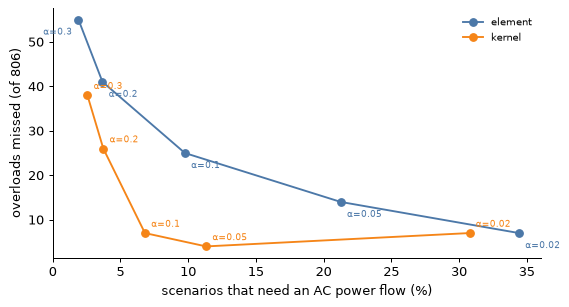

From `alpha` 0.3 to 0.02, the AC power flows rise from 1.9% to 34.4% of the scenarios with `element`, and the missed overloads fall from 55 to 7. Insecure scenarios are called secure only from `alpha` 0.05 up. The kernel's curve lies below: at the same share of AC power flows, it misses fewer overloads.

In [15]:
base = {
    "element": (config.read_text() + "save_figures: false\n", "screen"),
    "kernel": (
        kernel_config.read_text().replace(
            "n_eff_target: auto\ntuning:\n  grid: [100, 200, 400, 800, 1600]",
            f"n_eff_target: {tuned:g}",
        ),
        "kernel/screen",
    ),
}
sweep = []
for alpha in (0.3, 0.2, 0.1, 0.05, 0.02):
    for method, (text, screen_dir) in base.items():
        name = f"alpha/{method}_{alpha}"
        path = OUT / f"{name}.yaml"
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(
            text.replace("alpha: 0.1", f"alpha: {alpha}")
            .replace("variables: [Vm, Va, line_loading]", "variables: [line_loading]")
            .replace("outputs/", f"outputs/{name}/")
        )
        with redirect_stdout(StringIO()):
            for command in ("compute", "calibrate", "screen"):
                trustlayer([command, "--config", str(path)])
        screen = OUT / name / screen_dir
        table = pd.read_csv(screen / "status_by_stratum.csv")
        rows = table[
            (table["level"] == "scenario")
            & (table["variable"] == "all")
            & (table["stratum"] == "all")
            & (table["method"] == "interval")
        ].set_index("status")
        values = pd.read_parquet(screen / "screening_detail_line_loading.parquet")
        sweep.append(
            {
                "alpha": alpha,
                "method": method,
                "AC power flows (%)": 100
                * rows.loc["uncertain", "n"]
                / rows["n"].sum(),
                "overloads missed": int(
                    (
                        values["true_upper_violation"]
                        & (values["status"] == "within_limits")
                    ).sum()
                ),
                "insecure called secure": int(rows.loc["secure", "truly_violated"]),
            }
        )
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(figsize=(7, 3.6))
for method, color in (("element", "#4c78a8"), ("kernel", "#f58518")):
    rows = sweep[sweep["method"] == method]
    ax.plot(
        rows["AC power flows (%)"],
        rows["overloads missed"],
        "o-",
        color=color,
        label=method,
    )
    for _, row in rows.iterrows():
        # element's labels below its points, the kernel's above, so that they do not overlap
        below_left = method == "element" and row["alpha"] == 0.3
        ax.annotate(
            f"α={row['alpha']:g}",
            (row["AC power flows (%)"], row["overloads missed"]),
            textcoords="offset points",
            xytext=((-5 if below_left else 5), (-12 if method == "element" else 5)),
            ha="right" if below_left else "left",
            fontsize=7,
            color=color,
        )
ax.set_xlim(left=0)
ax.set_xlabel("scenarios that need an AC power flow (%)")
ax.set_ylabel(f"overloads missed (of {len(overloads)})")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
ends = sweep.set_index(["method", "alpha"])
called_secure = sweep.loc[sweep["insecure called secure"] > 0, "alpha"]
display(
    Markdown(
        f"From `alpha` 0.3 to 0.02, the AC power flows rise from {ends.loc[('element', 0.3), 'AC power flows (%)']:.1f}% to "
        f"{ends.loc[('element', 0.02), 'AC power flows (%)']:.1f}% of the scenarios with `element`, and the missed "
        f"overloads fall from {ends.loc[('element', 0.3), 'overloads missed']} to {ends.loc[('element', 0.02), 'overloads missed']}. "
        + (
            f"Insecure scenarios are called secure only from `alpha` {called_secure.min():g} up. "
            if len(called_secure)
            else "No insecure scenario is called secure at any `alpha`. "
        )
        + "The kernel's curve lies below: at the same share of AC power flows, it misses fewer overloads."
    )
)

Going down a curve, each step trades AC power flows for caught overloads; a curve that lies lower and to the left is the better screen. Here `alpha` is compared on the test set for illustration: to choose it for operation, use a separate validation set, or start from the miss rate you can accept.

### 8. Where the guarantee is weaker: values near the rating

The coverage guarantee holds per line and contingency level, averaged over all the scenarios of that level. It says less about particular kinds of scenarios within a level, and one kind matters most for screening: lines loaded close to their rating, where a small error decides between secure and insecure. Strata by predicted loading (`strat: pred_bins`, five bins of the predicted value, in place of the strata by outages) look like the natural fix, since they condition on the prediction itself; they are compared here too.

In [16]:
with redirect_stdout(StringIO()):
    variant("pred_bins", "strat: pred_bins\npred_n_bins: 5\n")


def near_rating_check(directory):
    rows = pd.read_parquet(
        directory / f"{GRID}_predictions_line_loading_with_intervals.parquet"
    )
    rows = rows[(rows["line_loading_target"] >= 0) & (rows["line_loading_pred"] >= 0)]
    above = rows["line_loading_target"] > rows["line_loading_pi_upper"]
    covered = rows["line_loading_target"].between(
        rows["line_loading_pi_lower"], rows["line_loading_pi_upper"]
    )
    near = (rows["line_loading_pred"] - 1.0).abs() < 0.1
    return pd.Series(
        {
            "above the upper bound: all values": above.mean(),
            f"above the upper bound: values predicted within 10% of the rating ({near.sum()})": above[
                near
            ].mean(),
            "coverage at the worst contingency level": covered.groupby(
                rows["scenario"].map(outages)
            )
            .mean()
            .min(),
        }
    )


near_rating = pd.DataFrame(
    {
        "element, n_outages": near_rating_check(OUT / "calibrated"),
        "element, pred_bins": near_rating_check(OUT / "pred_bins/calibrated"),
        "kernel, n_outages": near_rating_check(OUT / "kernel/calibrated"),
    }
)
display(
    Markdown(
        "Nominal: 5% above the upper bound (one tail of a 90% interval), 90% coverage."
    )
)
display(near_rating.map(lambda share: f"{share:.1%}"))
display(
    Markdown(
        f"Over all values, the upper bound is exceeded about 5% of the time or less, as promised. But lines predicted near "
        "their rating are where the model errs most, and there the upper bound is exceeded "
        f"{near_rating.iloc[1, 0]:.0%} of the time with `element`. Strata by predicted loading barely help "
        f"({near_rating.iloc[1, 1]:.0%}): their bins are cut on the predictions of all lines together, while bounds "
        "are fitted per line, so few calibration values of a line fall in its bin near the rating; and without strata "
        f"by outages, coverage drops to {near_rating.iloc[2, 1]:.0%} at N-5. The kernel, which weighs the calibration "
        f"scenarios most similar to each new one, brings it down to {near_rating.iloc[1, 2]:.0%} while keeping its "
        "coverage at every contingency level. The guarantee is an average over a contingency level, not a promise for "
        "every scenario in it: for decisions near the rating, the kernel or a smaller `alpha` give more margin."
    )
)

Nominal: 5% above the upper bound (one tail of a 90% interval), 90% coverage.

,"element, n_outages","element, pred_bins","kernel, n_outages"
above the upper bound: all values,5.4%,4.7%,3.3%
above the upper bound: values predicted within 10% of the rating (290),21.0%,17.9%,4.8%
coverage at the worst contingency level,88.5%,72.0%,90.0%


Over all values, the upper bound is exceeded about 5% of the time or less, as promised. But lines predicted near their rating are where the model errs most, and there the upper bound is exceeded 21% of the time with `element`. Strata by predicted loading barely help (18%): their bins are cut on the predictions of all lines together, while bounds are fitted per line, so few calibration values of a line fall in its bin near the rating; and without strata by outages, coverage drops to 72% at N-5. The kernel, which weighs the calibration scenarios most similar to each new one, brings it down to 5% while keeping its coverage at every contingency level. The guarantee is an average over a contingency level, not a promise for every scenario in it: for decisions near the rating, the kernel or a smaller `alpha` give more margin.

## What this showed

In [17]:
interval_misses = cell.loc[("interval", "secure"), "wrong"]
point_misses = cell.loc[("point", "secure"), "wrong"]
takeaways = [
    (
        f"The model's line-loading error grows from {problem['mean |error|'].iloc[0]:.5f} at N-1 to "
        f"{problem['mean |error|'].iloc[-1]:.3f} at N-5. Bounds fitted per number of outages cover "
        f"{coverage_by_k['n_outages'].min():.1%} to {coverage_by_k['n_outages'].max():.1%} of the true values at "
        f"every level; one set of bounds for all contingencies ranges from {coverage_by_k['one set'].min():.1%} "
        f"to {coverage_by_k['one set'].max():.1%}."
    ),
    (
        f"Screening on the point prediction lets {len(missed)} of the {len(overloads)} line overloads through; "
        f"the bounds catch {caught.sum()} of them. Per scenario, the point prediction calls {point_misses} "
        f"insecure scenarios secure, the bounds {interval_misses}."
    ),
    (
        f"Only the uncertain scenarios, {cell.loc[('interval', 'uncertain'), 'n'] / total:.0%} of the test set, "
        "need an AC power flow to decide. New scenarios get the same bounds and statuses, without their AC solution."
    ),
    (
        "Coverage is guaranteed per line and contingency level, not for lines near their rating, where true values "
        f"exceed the upper bound {near_rating.iloc[1, 0]:.0%} of the time. Kernel-weighted bounds, built on the "
        f"model's embeddings, bring that to {near_rating.iloc[1, 2]:.0%}, catch {caught_kernel.sum()} of the "
        f"{len(pairs)} overloads the point prediction misses, and need "
        f"{statuses.loc['kernel', 'uncertain: AC power flow']} AC power flows instead of "
        f"{statuses.loc['element', 'uncertain: AC power flow']}."
    ),
    "`alpha` trades AC power flows for missed overloads; choose it on separate data or from the miss rate you can accept.",
]
display(Markdown("\n".join(f"- {line}" for line in takeaways)))

- The model's line-loading error grows from 0.00007 at N-1 to 0.049 at N-5. Bounds fitted per number of outages cover 88.5% to 91.7% of the true values at every level; one set of bounds for all contingencies ranges from 69.4% to 99.9%.
- Screening on the point prediction lets 110 of the 806 line overloads through; the bounds catch 85 of them. Per scenario, the point prediction calls 74 insecure scenarios secure, the bounds 7.
- Only the uncertain scenarios, 10% of the test set, need an AC power flow to decide. New scenarios get the same bounds and statuses, without their AC solution.
- Coverage is guaranteed per line and contingency level, not for lines near their rating, where true values exceed the upper bound 21% of the time. Kernel-weighted bounds, built on the model's embeddings, bring that to 5%, catch 103 of the 110 overloads the point prediction misses, and need 330 AC power flows instead of 473.
- `alpha` trades AC power flows for missed overloads; choose it on separate data or from the miss rate you can accept.

## Where to go next

- The reports: `outputs/calibrated/coverage/summary.md`, `outputs/screen/summary.md` and `outputs/applied/status/summary.md`, with all their tables and figures.
- [Quick start](https://gridfm.github.io/gridfm-trustlayer/getting-started/quickstart/): the same workflow on your own grid and model.
- [Reading the results](https://gridfm.github.io/gridfm-trustlayer/user-guide/results/): every file and column.
- [Choosing a setup](https://gridfm.github.io/gridfm-trustlayer/user-guide/choosing-a-setup/): `cp_type`, `strat`, `alpha`.